In [2]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

from matplotlib import pyplot as plt

from environments.qm_env_lindblad import Lindblad_Environment
from SAC.environment.qm_env_wrapper import GymEnvironment
from SAC.evaluate import get_control_sequence
from SAC.train import train

In [3]:
seed = 0

Nb = 2
Nc = Nb * 3

ENV_PARAMS = {
    #general
    "wc": 1.0,
    "wb": 1.0,

    "Nc": Nb * 3,
    "Nb": Nb,

    "Nc_max": Nc * 3,

    "kappa": 0.2,
    
    "dt": 0.2,
    "tau": 5.6,

    #for SAC
    "min_u": -0.3,
    "max_u": 0.3,

    "objective": "ergotropy_full",

    "reward_coeff": 1.0
}

HYPER_PARAMS = {
    "BATCH_SIZE": 256,            #batch size

    "LR": 0.001,                  #learning rate for Q and Pi loss
    "ALPHA_LR": 0.003,            #learning rate to tune the temperature parameters alpha 

    "H_START": 0.72,              #initial target entropy of the policy
    "H_END": -3.,                 #final target entropy of the policy
    "H_DECAY": 200000,            #exponential decay of the target entropy of the policy

    "C_START": [1./Nb, 0.],       #initial weights for energy and ergotropy to compute the reward (Eqs. S38 - S39)
    "C_END": [0., 1.],            #final weights for energy and ergotropy to compute the reward (Eqs. S38 - S39)
    "C_MEAN": 40000,              #timestep number where the weights are half way between start and end
    "C_WIDTH": 20000,             #width in timesteps to transition from start and end weights        

    "REPLAY_MEMORY_SIZE": 150000, #size of the replay buffer

    "POLYAK": 0.995,              #polyak coefficient

    "GAMMA": 0.993,               #RL discount factor

    "HIDDEN_SIZES": (512,256),    #size of hidden layers of the neural networks
    
    "INITIAL_RANDOM_STEPS": 5000, #number of initial uniformly random steps
    "UPDATE_AFTER": 1000,         #start minimizing loss function after initial steps
    "UPDATE_EVERY": 50,           #performs this many updates every this many steps

    "USE_CUDA": True,             #use cuda for computation

    "MIN_COV_EIGEN": 1.e-7,       #security parameter for the covariance matrix of the policy
}

In [4]:
env = Lindblad_Environment(params = ENV_PARAMS)

gym_env = GymEnvironment(env, ENV_PARAMS)

In [5]:
agent = train(gym_env, HYPER_PARAMS, seed = seed, steps = 50000)

SAC Training:   0%|          | 0/50000 [00:00<?, ?step/s]

In [6]:
times, actions, final_info = get_control_sequence(gym_env, agent, seed = seed)
history = env.replay(actions)

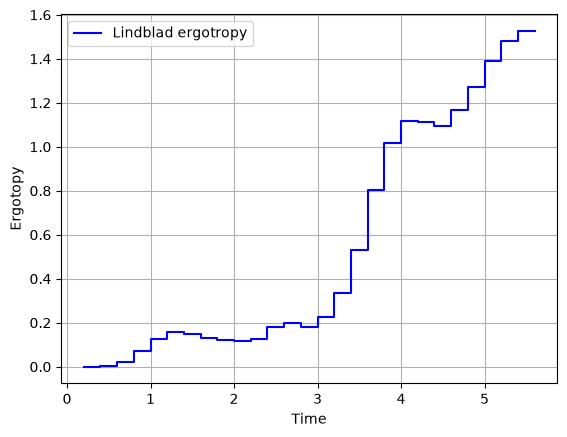

In [ ]:
key = "ergotropy_full"

plt.step(
    [h["time"] for h in history], 
    [h[key] for h in history],
    c = "blue",
    label = "Lindblad ergotropy"
)

plt.legend()
plt.grid()

plt.xlabel("Time")
plt.ylabel("Ergotopy")

plt.show()

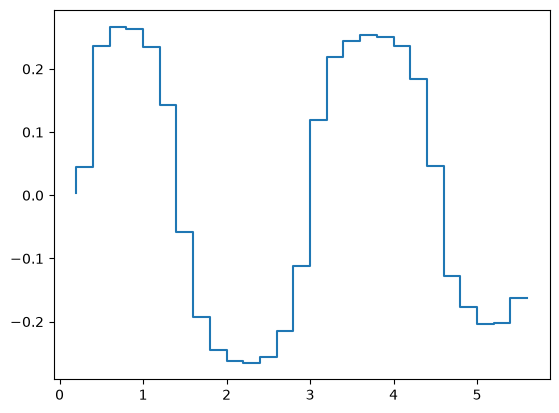

In [9]:
plt.step([h["time"] for h in history], actions)
plt.show()